In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

In [3]:
df = pd.read_csv('knn_student_result_large_dataset.csv')
df.head()

,Age,Study_Hours,Attendance,Result
0,24,3.0,53.8,Fail
1,21,1.9,60.6,Fail
2,30,5.7,60.5,Pass
3,28,8.6,75.3,Pass
4,25,1.6,40.0,Fail


#  Data Visualization

In [4]:
df.shape

(500, 4)

In [5]:
df.info

<bound method DataFrame.info of      Age  Study_Hours  Attendance Result
0     24          3.0        53.8   Fail
1     21          1.9        60.6   Fail
2     30          5.7        60.5   Pass
3     28          8.6        75.3   Pass
4     25          1.6        40.0   Fail
..   ...          ...         ...    ...
495   29         11.0        87.7   Pass
496   27          2.4        42.2   Fail
497   24          3.6        67.6   Fail
498   27          2.8        54.1   Fail
499   22          3.0        59.2   Fail

[500 rows x 4 columns]>

In [6]:
df.isnull().sum()

Age            0
Study_Hours    0
Attendance     0
Result         0
dtype: int64

In [7]:
df.columns

Index(['Age', 'Study_Hours', 'Attendance', 'Result'], dtype='str')

In [8]:
df.describe()

,Age,Study_Hours,Attendance
count,500.000000,500.000000,500.000000
mean,23.900000,6.545600,73.145600
std,3.774984,3.118321,15.403438
min,18.000000,1.000000,40.000000
25%,21.000000,3.800000,61.250000
50%,24.000000,6.800000,74.100000
75%,27.000000,9.100000,85.500000
max,30.000000,12.000000,100.000000


In [9]:
df['Result'].value_counts()

Result
Pass    292
Fail    208
Name: count, dtype: int64

<Axes: xlabel='Result'>

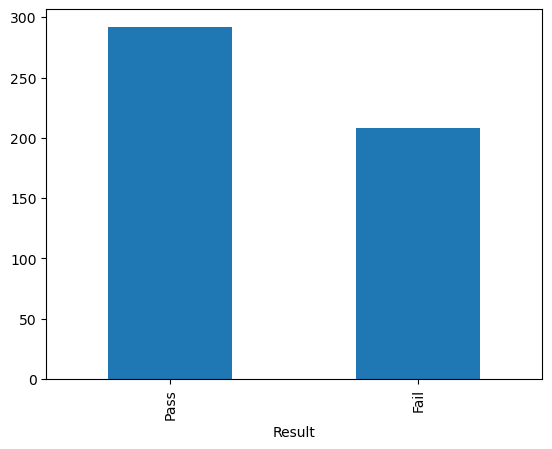

In [10]:
df['Result'].value_counts().plot(kind='bar')

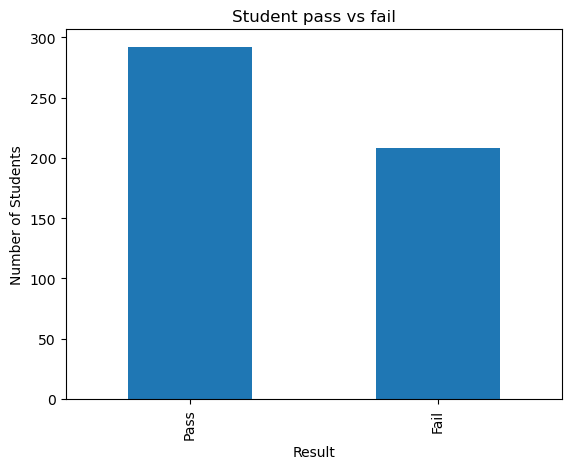

In [11]:
df['Result'].value_counts().plot(kind='bar')

plt.title('Student pass vs fail')
plt.xlabel('Result')
plt.ylabel('Number of Students')
plt.show()

<!-- Seperate X and Y -->

#  Seperate X and y

In [12]:
X = df[["Age","Study_Hours", "Attendance"]]
y = df["Result"]

# Split into training and testing data

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state=42
)

In [14]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 3)
Testing data: (100, 3)


# Feature Scaling

In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# fit() = Learn
# transform() = Apply
# fit_transform = Learn + Apply

# Import KNN

In [16]:
from sklearn.neighbors import KNeighborsClassifier

# Create a KNN classifier with 5 neighbors
knn = KNeighborsClassifier(n_neighbors= 5)

# Train the model

In [17]:
knn.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


#  Make Prediction

In [18]:
y_pred = knn.predict(X_test_scaled)

y_pred[:10]

array(['Fail', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass', 'Fail',
       'Pass', 'Pass'], dtype=object)

#  Compare actual and predicted

In [19]:
comparison = pd.DataFrame({
"Actual" : y_test.values,
"Predicted" : y_pred
})

comparison.head(20)

,Actual,Predicted
0,Fail,Fail
1,Pass,Pass
2,Pass,Pass
3,Fail,Pass
4,Pass,Pass
5,Pass,Pass
6,Pass,Pass
7,Fail,Fail
8,Pass,Pass
9,Pass,Pass


#  Calculate accuracy

In [20]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, '%')

Accuracy: 0.9
Accuracy percentage: 90.0 %


#  Confusion Matrix

In [21]:
from sklearn.metrics import confusion_matrix
cm =confusion_matrix(y_test, y_pred)
print(cm)

[[40  7]
 [ 3 50]]


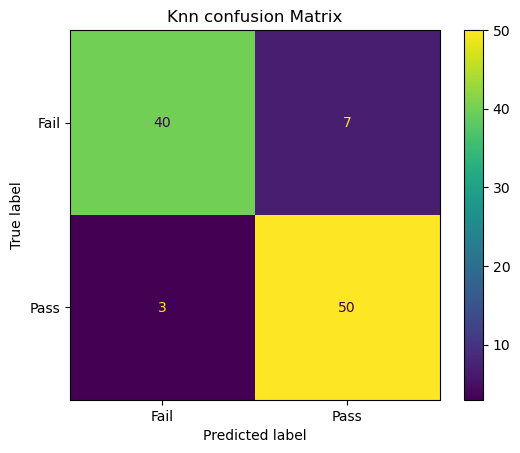

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

plt.title("Knn confusion Matrix")
plt.show()

#  Classification Report

In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

        Fail       0.93      0.85      0.89        47
        Pass       0.88      0.94      0.91        53

    accuracy                           0.90       100
   macro avg       0.90      0.90      0.90       100
weighted avg       0.90      0.90      0.90       100



#  Test different K values

In [24]:
k_values = range(1,21)

accuracies = []

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

In [25]:
best_k = k_values[np.argmax(accuracies)]
best_accuracy = max(accuracies)

print("best K:",best_k)
print("Best Accuracy:", best_accuracy)

best K: 16
Best Accuracy: 0.92


#  Visulaize K vs Accuracy

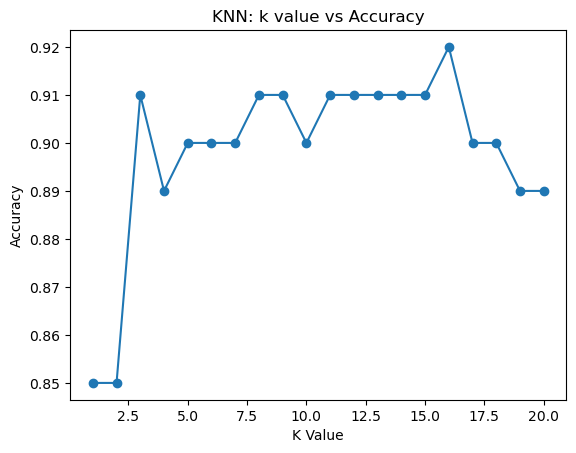

In [26]:
plt.plot(k_values, accuracies, marker = "o")

plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN: k value vs Accuracy")

plt.show()

#  Train final model with best K

In [27]:
best_knn = KNeighborsClassifier(n_neighbors=  best_k)

best_knn.fit(X_train_scaled, y_train)

,n_neighbors,16
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [28]:
final_predictions = best_knn.predict(X_test_scaled)

final_accuracy = accuracy_score(y_test, final_predictions)

print("Final Accurqacy:", final_accuracy)

Final Accurqacy: 0.92


# Predict a completely new student 

In [29]:
new_student = pd.DataFrame({
    "Age" : [23],
    "Study_Hours" :[8],
    "Attendance" : [85]
})
new_student

,Age,Study_Hours,Attendance
0,23,8,85


In [30]:
#  Scale it
new_student_scaled = scaler.transform(new_student)

In [31]:
#  Predict
prediction = best_knn.predict(new_student_scaled)

print("Prediction Result:", prediction[0])

Prediction Result: Pass


# Model Deployment

In [32]:
#  Save the model and scaler for future use

import joblib

joblib.dump(best_knn, "knn_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

#  Create a prediction function

In [33]:
def predict_result(age, study_hours, attendance):
    new_student =[[age, study_hours, attendance]]

    new_student_scaled = scaler.transform(new_student)

    prediction = best_knn.predict(new_student_scaled)

    return prediction[0]

In [34]:
result = predict_result(23,8,85)

print(result)

Pass


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
